## CLASSIFICATION PART B : 
# Here we will be covering algorithms 
6 Random Forest Classifier	feature importance; n_estimators \
  7	AdaBoost Classifier	n_estimators, learning_rate \
  8	Gradient Boosting Classifier	learning rate (sklearn GBM) \
  9	Bagging Classifier	Decision Tree as base estimator \
  10 MLP Classifier (Neural Network)

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score  # Part-A + final per-class report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,StratifiedGroupKFold
import os


# text columns as object dtype on every pandas version, so the categorical
# columns are detected the same way everywhere
pd.set_option('future.infer_string', False)
# project root, whether the notebook runs from notebooks/ or from the root
ROOT = '..' if os.path.isdir(os.path.join('..', 'data')) else '.'


In [2]:
folder = 'data/raw/TON_IoT'

path = os.path.join(ROOT, folder, 'train_test_network.csv')

df = pd.read_csv(path)

df

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211038,192.168.1.32,48286,176.28.50.165,80,tcp,http,65.376610,2665,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211039,192.168.1.32,48288,176.28.50.165,80,tcp,http,65.710346,1987,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211040,192.168.1.32,48292,176.28.50.165,80,tcp,http,65.766512,3922,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211041,192.168.1.32,48294,176.28.50.165,80,tcp,http,65.753940,2401,322,S3,...,0,0,-,-,-,-,-,-,1,xss


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

In [4]:
df.isna().sum()
df['http_user_agent'].value_counts()

http_user_agent
-                                                                                                                                    210756
Microsoft-Delivery-Optimization/10.0                                                                                                     62
Microsoft-Windows/10.0 UPnP/1.0                                                                                                          47
Ruby                                                                                                                                     31
DAFUPnP                                                                                                                                  27
User-Agent: Microsoft-DLNA DLNADOC/1.50                                                                                                  24
Windows-Update-Agent/10.0.10011.16384 Client-Protocol/1.91                                                                               21
Micr

In [5]:
df = df.drop_duplicates(ignore_index=True)
df

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190469,192.168.1.32,48286,176.28.50.165,80,tcp,http,65.376610,2665,322,S3,...,0,0,-,-,-,-,-,-,1,xss
190470,192.168.1.32,48288,176.28.50.165,80,tcp,http,65.710346,1987,322,S3,...,0,0,-,-,-,-,-,-,1,xss
190471,192.168.1.32,48292,176.28.50.165,80,tcp,http,65.766512,3922,322,S3,...,0,0,-,-,-,-,-,-,1,xss
190472,192.168.1.32,48294,176.28.50.165,80,tcp,http,65.753940,2401,322,S3,...,0,0,-,-,-,-,-,-,1,xss


# log1p on duration, src_bytes, dst_bytes, src_pkts, dst_pkts 
### Are to be log1p transformed as their values are so far apart for some network flows 
### means it is right skewed and then use standard scalar over the columns
### Collapse 5 DNS booleans → 1 dns_present (16.5%, healthy)

## Here we Are StratifiedGroupKFold as it allows when 2 groups are present instead of dividing its values among sets it makes sure whole groups data stays in either of the sets 
### In case of cancer patients
### • The model is forced to learn actual features of cancer, not just recognize specific patients.


In [6]:
NEED = ["proto","service","conn_state","duration","src_bytes","dst_bytes","missed_bytes",
        "src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes","dns_qtype","dns_rcode",
        "dns_AA","dns_RD","dns_RA","dns_rejected","dns_qclass","dst_port","src_ip","label","type"]
LOG  = ["duration","src_bytes","dst_bytes","src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes"]
CAT  = ["proto","service","conn_state"]
DNS_S   = ["dns_AA","dns_RD","dns_RA","dns_rejected"]
DROP_AFT = DNS_S + ["dns_qclass", "missed_bytes", "src_ip"]

cols = [
    'http_user_agent',
    'http_orig_mime_types',
    'http_resp_mime_types',
    'weird_name',
    'weird_addl',
    'weird_notice'
]
cols1 = [
    'http_trans_depth',
    'http_method',
    'http_uri',
    'http_version'
]


ssl_keep = [
    "ssl_version",
    "ssl_cipher",
    "ssl_resumed",
    "ssl_established"
]

ssl_drop = ["ssl_subject", "ssl_issuer"]

df[ssl_keep] = df[ssl_keep].replace("-", "Unknown")
df = df.drop(columns=ssl_drop)

df=df.drop(cols+cols1, axis=1)


df = df.sample(frac=1,random_state=42,ignore_index=True)

train,test = next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42).split(df,df['type'],groups=df['src_ip']))

# here as StratifiedGroupKFold splits and produces 5 divisions out of these the next() chooses
# first split
X_train = df.iloc[train]
X_test = df.iloc[test]

fit = {
  "dur_hi":X_train["duration"].quantile(0.999),
  "ports": set(X_train["dst_port"].value_counts().head(10)),
  "cats":{c:pd.Categorical(X_train[c]).categories for c in CAT}
}

def build(d,fit):
  df = d.copy()
  df['dns_present'] = d[DNS_S].ne('-').any(axis=1).astype("int8")
  df['dns_query_parsed'] = d['service'].eq("dns").astype("int8")
  df['has_missed'] = df['missed_bytes'].gt(0).astype("int8")
  df['duration'] = df['duration'].clip(upper=fit["dur_hi"]) # ,d['dst_port]
  df[LOG] = np.log1p(df[LOG].to_numpy()) # we are applying log transformations
  df["dst_port"] = np.where(df['dst_port'].isin(fit["ports"]),df['dst_port'],-1).astype("int16")
  for c in CAT:
    df[c] =pd.Categorical(df[c],categories=fit['cats'][c]).codes.astype("int16")
  return df.drop(columns=DROP_AFT+["type","label"])


Y_train,Y_test = df["type"].iloc[train].values,df["type"].iloc[test].values

X_train,X_test = build(X_train,fit), build(df.iloc[test],fit)

X_train

# DROP 18 COLUMNS AS THEIR INCLUSION SPOILS THE CLUSTERING TO A HIGH VALUE 
# LEADING TO INCOSISTENT PREDICTIONS

# here dst_port can be 80,98,443 and -1(if not in top10) 
# writing .cat.codes makes 80 encoded as 1 and 98 as 2 and 443 as 3 and -1 as 4

# missed_bytes column correspond to when both direction s of a TCP conversations and send payload to each other . if some packets go missing the bytes inside those missing packets can't be recovered which are recorded as missed_bytes

,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,src_pkts,...,ssl_version,ssl_cipher,ssl_resumed,ssl_established,http_request_body_len,http_response_body_len,http_status_code,dns_present,dns_query_parsed,has_missed
1,49989,192.168.1.37,-1,1,0,0.000095,0.000000,0.000000,1,0.693147,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
3,48624,192.168.1.190,-1,1,5,0.002208,5.049856,6.480045,10,1.791759,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
4,37180,52.28.231.150,-1,1,0,0.000000,0.000000,0.000000,11,0.693147,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
6,60526,192.168.1.152,-1,1,0,0.001271,0.000000,0.000000,7,1.098612,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
7,1553,192.168.1.195,-1,1,0,0.246755,0.000000,0.000000,6,4.795791,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190466,54524,192.168.1.152,-1,1,5,0.001914,5.036953,6.139885,10,1.791759,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
190468,1226,192.168.1.152,-1,1,0,0.210555,0.000000,0.000000,6,4.795791,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
190469,52156,192.168.1.1,-1,1,5,0.006497,5.257495,6.899723,10,1.791759,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0
190471,33292,192.168.1.195,-1,1,5,0.010453,5.049856,6.886532,10,1.791759,...,Unknown,Unknown,Unknown,Unknown,0,0,0,0,0,0


In [7]:
from sklearn.ensemble import (
  RandomForestClassifier,
  AdaBoostClassifier,
  GradientBoostingClassifier,
  BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_test.select_dtypes(include='object').columns.tolist()


numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])


processor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols)
])

X_train1 = processor.fit_transform(X_train)
X_test1 = processor.transform(X_test)

feature_names = processor.get_feature_names_out()

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

processor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols)
])

X_train1 = processor.fit_transform(X_train)
X_test1 = processor.transform(X_test)

# Names for BOTH numerical and categorical features
feature_names = processor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train1.toarray() if hasattr(X_train1, "toarray") else X_train1,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test1.toarray() if hasattr(X_test1, "toarray") else X_test1,
    columns=feature_names,
    index=X_test.index
)

print("Train shape:", X_train_df.shape)
print("Test shape:", X_test_df.shape)

X_train_df

Train shape: (123473, 165)
Test shape: (67001, 165)


,num__src_port,num__dst_port,num__proto,num__service,num__duration,num__src_bytes,num__dst_bytes,num__conn_state,num__src_pkts,num__src_ip_bytes,...,cat__ssl_cipher_TLS_AES_128_GCM_SHA256,cat__ssl_cipher_TLS_ECDHE_RSA_WITH_AES_128_GCM_SHA256,cat__ssl_cipher_Unknown,cat__ssl_cipher_infrequent_sklearn,cat__ssl_resumed_F,cat__ssl_resumed_T,cat__ssl_resumed_Unknown,cat__ssl_established_F,cat__ssl_established_T,cat__ssl_established_Unknown
1,0.464720,-0.011384,-0.591837,-0.759393,-0.357891,-0.795590,-0.646065,-1.309432,-0.512292,-0.497642,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.374406,-0.011384,-0.591837,1.774126,-0.355598,1.049942,1.341354,1.022999,0.508282,0.609391,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-0.382774,-0.011384,-0.591837,-0.759393,-0.357994,-0.795590,-0.646065,1.282158,-0.512292,-0.457385,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6,1.161890,-0.011384,-0.591837,-0.759393,-0.356614,-0.795590,-0.646065,0.245522,-0.135628,-0.068987,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
7,-2.739998,-0.011384,-0.591837,-0.759393,-0.090142,-0.795590,-0.646065,-0.013637,3.298927,1.854390,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190466,0.764774,-0.011384,-0.591837,1.774126,-0.355916,1.045227,1.237028,1.022999,0.508282,0.606966,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
190468,-2.761634,-0.011384,-0.591837,-0.759393,-0.129437,-0.795590,-0.646065,-0.013637,3.298927,1.854390,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
190469,0.608097,-0.011384,-0.591837,1.774126,-0.350942,1.125827,1.470069,1.022999,0.508282,0.584603,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
190471,-0.640020,-0.011384,-0.591837,1.774126,-0.346647,1.049942,1.466023,1.022999,0.508282,0.547756,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [8]:
  # RandomForestClassifier,
  # AdaBoostClassifier,
  # GradientBoostingClassifier,
  # BaggingClassifier,
# MLPClassifier
models = {
  "RandomForest": RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1),
  "AdaBoost": AdaBoostClassifier(n_estimators=100,learning_rate=0.1,random_state=42),
  "Gradient Boost": GradientBoostingClassifier(n_estimators=100,max_depth=4,random_state=42),
  "Bagging": BaggingClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
  "MLP":MLPClassifier(hidden_layer_sizes=(100,),
                      activation="relu",solver="adam",max_iter=300,random_state=42)
}


In [9]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

FITTED = {}   # every fitted model by name, so later cells can reuse the real one


def cls_metrics(y_true, y_pred, model=None, X=None, name=None):
    """Accuracy, weighted precision/recall/F1, macro F1 and ROC-AUC (one-vs-rest).

    ROC-AUC is the mean one-vs-rest AUC over the classes present in y_true, from predict_proba
    (or decision_function for models without probabilities, e.g. SVC)."""
    m = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (w)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall (w)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": np.nan,
    }
    if model is not None and X is not None:
        scores = model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)
        y_arr = np.asarray(y_true, dtype=object)
        cls = list(model.classes_)
        present = [c for c in cls if (y_arr == c).any()]
        m["ROC-AUC (OvR)"] = float(np.mean([roc_auc_score(y_arr == c, scores[:, cls.index(c)]) for c in present]))
        if name is not None:
            FITTED[name] = model
    return m


# Store results keyed by model name so re-running a cell UPDATES its row
# instead of appending a duplicate (fixes identical repeated rows).
_model_rows = {}


def add_result(name, m, split="test"):
    _model_rows[name] = {
        "Model": name,
        "Accuracy " + split: m["Accuracy"],
        "Precision " + split: m["Precision (w)"],
        "Recall " + split: m["Recall (w)"],
        "F1w " + split: m["F1 weighted"],
        "F1m " + split: m["F1 macro"],
        "ROC-AUC " + split: m["ROC-AUC (OvR)"],
    }
    return _model_rows


def results_table():
    import pandas as pd
    return pd.DataFrame(list(_model_rows.values()))

## 6.RandomForest CLASSIFIER

In [10]:
name = "Random Forest"
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

        Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984


## 7.ADABoost Classifier

In [11]:
from sklearn.tree import DecisionTreeClassifier

name = "AdaBoost"
# Default base estimator is a 1-node decision STUMP which is far too weak for
# 10 imbalanced classes (it only predicted ~5 classes, ~10% acc). Using a
# depth-3 tree as the weak learner lifts accuracy to ~62% (all 10 classes).
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42,
)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

        Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
     AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157


## 8.GradientBoosting Classifier

In [12]:
name="GradientBoostingClassifier"

model = GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))



                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892


### Hyperparameter tuning — Gradient Boosting (fast)

Top-1 by test weighted F1. Instead of an exhaustive grid over 48 fits on the full 123k train rows, a `RandomizedSearchCV` (5 candidates) runs on a **stratified 35% subsample**, then the winning configuration is refit once on the full training set for the reported test score. `f1_weighted` scoring suits the 10 imbalanced classes (`mitm` is 0.55% of rows). Test split is never searched.

In [13]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

name = "GBC (tuned)"

# Stratified 35% subsample of the TRAINING split -> ~3x cheaper per fit.
X_all = np.asarray(X_train_df, dtype=np.float64)
Y_all = np.asarray(Y_train, dtype=object)
X_s, _, y_s, _ = train_test_split(
    X_all, Y_all, train_size=0.35, stratify=Y_all, random_state=42
)

gbc_grid = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
}

search_gbc = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    gbc_grid,
    n_iter=5,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
)
search_gbc.fit(X_s, y_s)

print("Best params :", search_gbc.best_params_)
print(f"Best CV F1w : {search_gbc.best_score_:.6f} (on 35% subsample)")

# Refit the winner ONCE on the full training set for an honest test score.
model = GradientBoostingClassifier(random_state=42, **search_gbc.best_params_)
model.fit(X_train_df, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_df), model, X_test_df, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

Best params : {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.05}
Best CV F1w : 0.988799 (on 35% subsample)


                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877


## 9.Bagging Classifier

In [14]:
name = "Bagging"

# BUG FIX: was `max_samples=1` (int = 1 sample/tree -> 1-node stump, ~9.8% acc,
# predicted only 1 class). Correct: max_samples=1.0 (fraction = 100% bootstrap).
# max_features=0.3 subsamples features per split (Random-Forest-style), which
# decorrelates the trees and lifts accuracy to ~72% (and runs ~5x faster).
model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=1.0,
    max_features=0.3,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324


### Hyperparameter tuning


Top-2 by test weighted F1. Same fast protocol: `RandomizedSearchCV` (6 candidates, 3-fold CV) on a stratified 35% subsample, winner refit once on the full training set. Shallow trees + `n_jobs=-1` make each fit cheap.

In [15]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

name = "Bagging (tuned)"

X_all = np.asarray(X_train_df, dtype=np.float64)
Y_all = np.asarray(Y_train, dtype=object)
X_s, _, y_s, _ = train_test_split(
    X_all, Y_all, train_size=0.35, stratify=Y_all, random_state=42
)

bag_grid = {
    "n_estimators": [150, 200],
    "max_samples": [0.7, 0.85],
    "max_features": [0.2, 0.3],
    "estimator__max_depth": [None, 30],
    "estimator__min_samples_leaf": [1, 5],
}

search_bag = RandomizedSearchCV(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        bootstrap=True,
        random_state=42,
        n_jobs=1,
    ),
    bag_grid,
    n_iter=8,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="f1_weighted",
    random_state=42,
    n_jobs=4,
)
search_bag.fit(X_s, y_s)

print("Best params :", search_bag.best_params_)
print(f"Best CV F1w : {search_bag.best_score_:.6f} (on 35% subsample)")

bag_best = dict(search_bag.best_params_)
tree_depth = bag_best.pop("estimator__max_depth", None)
tree_leaf = bag_best.pop("estimator__min_samples_leaf", 1)
model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42, max_depth=tree_depth, min_samples_leaf=tree_leaf),
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    **bag_best,
)
model.fit(X_train_df, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_df), model, X_test_df, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

Best params : {'n_estimators': 200, 'max_samples': 0.7, 'max_features': 0.2, 'estimator__min_samples_leaf': 1, 'estimator__max_depth': 30}
Best CV F1w : 0.984566 (on 35% subsample)


                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663


## 10.MLP Classifier

In [16]:
name = "Neural Network"

# BUG FIX: early_stopping=True crashed with
#   TypeError: ufunc 'isnan' not supported for the input types
# because pandas 3.0 stores the string target as an ArrowStringArray and
# sklearn 1.8 runs np.isnan() on the string predictions during early-stopping
# validation scoring. Removing early_stopping avoids that code path and trains
# fine on the string labels (acc ~0.66, all 10 classes).
model = MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=300,
        random_state=42
    )


X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476


## Part A models on the TON_IoT processed matrix
The 5 algorithms from `03_classification.ipynb` (Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC-RBF), trained here on this notebook's own preprocessed TON_IoT matrix (`X_train_df`/`X_test_df`, 123473 x 165 / 67001 x 165) instead of that notebook's UNSW-NB15 pipeline. Hyperparameters are kept identical; SVC-RBF keeps its 12k stratified train-subsample rule (RBF scales quadratically). Scores append to the same `results` table, so the final leaderboard covers all 12 configs.



In [17]:
# --- Part-A setup: numpy views, 12k SVC subsample, fitted-model cache ---
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
X_tr = np.asarray(X_train_df, dtype=np.float64)
X_te = np.asarray(X_test_df, dtype=np.float64)
y_tr = np.asarray(Y_train, dtype=object)
y_te = np.asarray(Y_test, dtype=object)
# SVC-RBF 12k stratified subsample (same rule as 03_classification.ipynb)
SUBSAMPLE_N = 12000
rng = np.random.RandomState(42)
_parts = []
for cls in sorted(set(y_tr.tolist())):
    idx = np.where(y_tr == cls)[0]
    n = max(1, int(round(len(idx) * SUBSAMPLE_N / len(X_tr))))
    _parts.append(rng.choice(idx, size=min(n, len(idx)), replace=False))
sub_idx = np.sort(np.concatenate(_parts))
X_sub, y_sub = X_tr[sub_idx], y_tr[sub_idx]
print('SVC subsample:', X_sub.shape)
fittedA = {}



SVC subsample: (11999, 165)


In [18]:
# SVC follows the 12k-subsample rule; the rest train on the full matrix.
SUBSAMPLE_MODELS = {'SVC (RBF)'}
print('subsample rule:', SUBSAMPLE_MODELS)




subsample rule: {'SVC (RBF)'}


### A1. Logistic Regression
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [19]:
# --- Part-A: Logistic Regression ---
name = "Logistic Regression"
model = LogisticRegression(C=1.0, max_iter=3000, class_weight='balanced', n_jobs=-1)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



C:\Users\himes\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[Logistic Regression   ] Accuracy=0.6443 Precision (w)=0.6720 Recall (w)=0.6443 F1 weighted=0.6135 F1 macro=0.3967 ROC-AUC (OvR)=0.8627  fit=2489.9s
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476
       Logi

### A2. K-Nearest Neighbors
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [20]:
# --- Part-A: K-Nearest Neighbors ---
name = "K-Nearest Neighbors"
model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[K-Nearest Neighbors   ] Accuracy=0.5993 Precision (w)=0.6875 Recall (w)=0.5993 F1 weighted=0.6197 F1 macro=0.4061 ROC-AUC (OvR)=0.8342  fit=1.1s
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476
       Logisti

### A3. Gaussian NB
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [21]:
# --- Part-A: Gaussian NB ---
name = "Gaussian NB"
model = GaussianNB()
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[Gaussian NB           ] Accuracy=0.2964 Precision (w)=0.8224 Recall (w)=0.2964 F1 weighted=0.3959 F1 macro=0.2453 ROC-AUC (OvR)=0.8261  fit=1.4s
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476
       Logisti

### A4. Decision Tree
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [22]:
# --- Part-A: Decision Tree ---
name = "Decision Tree"
model = DecisionTreeClassifier(max_depth=None, class_weight='balanced', random_state=42)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[Decision Tree         ] Accuracy=0.6298 Precision (w)=0.8653 Recall (w)=0.6298 F1 weighted=0.6239 F1 macro=0.4103 ROC-AUC (OvR)=0.8453  fit=3.7s
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476
       Logisti

### A5. SVC (RBF)
Same hyperparameters as `03_classification.ipynb`. Trained on the 12k stratified subsample (RBF rule).


In [23]:
# --- Part-A: SVC (RBF) ---
name = "SVC (RBF)"
model = SVC(kernel='rbf', C=1.0, class_weight='balanced')
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[SVC (RBF)             ] Accuracy=0.6781 Precision (w)=0.6852 Recall (w)=0.6781 F1 weighted=0.6399 F1 macro=0.4754 ROC-AUC (OvR)=0.8942  fit=8.8s
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
             Random Forest       0.666766        0.814661     0.666766  0.605872  0.406468      0.973984
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
            Neural Network       0.644364        0.776500     0.644364  0.600675  0.412796      0.948476
       Logisti

## Final leaderboard — all 12 configs
Ranked by test weighted F1: the 7 Part-B configs (5 baselines + 2 tuned) plus the 5 Part-A configs above, all trained and scored on the same TON_IoT processed matrix and `src_ip`-grouped test split. Also persisted to `results/classification_12model_ton_iot.csv`.



In [24]:
# --- Final 12-model leaderboard ---
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
print(board.to_string(index=False))
print()
print('Best model:', board.iloc[0]['Model'], '| F1w test = %.6f' % board.iloc[0]['F1w test'])
os.makedirs(os.path.join(ROOT, 'results'), exist_ok=True)
board.to_csv(os.path.join(ROOT, 'results/classification_12model_ton_iot.csv'), index=False)
print('Saved: results/classification_12model_ton_iot.csv')




                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
               GBC (tuned)       0.836525        0.940428     0.836525  0.874187  0.534530      0.996877
GradientBoostingClassifier       0.757839        0.921142     0.757839  0.752968  0.520674      0.991892
           Bagging (tuned)       0.723198        0.969592     0.723198  0.730183  0.488202      0.994663
                   Bagging       0.726735        0.907353     0.726735  0.692078  0.462044      0.995324
                  AdaBoost       0.641095        0.928599     0.641095  0.665019  0.451984      0.948157
                 SVC (RBF)       0.678079        0.685219     0.678079  0.639917  0.475385      0.894164
             Decision Tree       0.629767        0.865330     0.629767  0.623938  0.410323      0.845327
       K-Nearest Neighbors       0.599304        0.687485     0.599304  0.619656  0.406069      0.834168
       Logistic Regression       0.644349        0.6719

In [25]:



# --- Per-class P/R/F1 for the winning model (test set) ---
best_name = board.iloc[0]['Model']
best_model = FITTED[best_name]   # the winning model itself
yp = best_model.predict(X_te)
labels = sorted(set(np.asarray(y_te, dtype=object).tolist()))
prec = precision_score(y_te, yp, labels=labels, average=None, zero_division=0)
rec = recall_score(y_te, yp, labels=labels, average=None, zero_division=0)
f1 = f1_score(y_te, yp, labels=labels, average=None, zero_division=0)
per = pd.DataFrame({'class': labels, 'precision': prec, 'recall': rec, 'f1': f1})
print('Per-class report -', best_name, '(test set)')
print(per.to_string(index=False))
per.to_csv(os.path.join(ROOT, 'results/classification_12model_per_class.csv'), index=False)
print('Saved: results/classification_12model_per_class.csv')



C:\Users\himes\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


Per-class report - GBC (tuned) (test set)
    class  precision   recall       f1
     ddos   0.984066 0.633952 0.771129
      dos   0.999357 0.791504 0.883369
injection   0.894092 0.928935 0.911181
   normal   0.871774 0.982607 0.923878
 password   0.805224 0.985719 0.886376
 scanning   0.980603 0.958386 0.969367
Saved: results/classification_12model_per_class.csv


## 5-fold cross-validation of the top two models

The two best configurations (GBC tuned and Bagging tuned) are cross-validated on the **training set only** with `StratifiedGroupKFold(n_splits=5)` grouped by `src_ip`. Each validation fold therefore holds machines that its training folds never saw, the same design as the held-out test split. The settings are the tuned ones found by the searches above; the test set is not used.

In [26]:
# --- 5-fold grouped cross-validation of the top two models (training set only) ---
import time
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

X_cv = np.asarray(X_train_df, dtype=np.float64)
y_cv = np.asarray(Y_train, dtype=object)
groups_cv = df['src_ip'].iloc[train].values          # source machine of every training row
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

top2 = {
    'GBC (tuned)': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=5,
                                              subsample=0.8, random_state=42),
    'Bagging (tuned)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42, max_depth=30),
                                         n_estimators=200, max_samples=0.7, max_features=0.2,
                                         bootstrap=True, random_state=42, n_jobs=4),
}

cv_rows = []
for name, est in top2.items():
    t0 = time.time()
    res = cross_validate(est, X_cv, y_cv, groups=groups_cv, cv=cv5,
                         scoring=['f1_weighted', 'f1_macro', 'accuracy'], n_jobs=5)
    cv_rows.append({
        'Model': name,
        'CV F1w mean': res['test_f1_weighted'].mean(), 'CV F1w std': res['test_f1_weighted'].std(),
        'CV F1m mean': res['test_f1_macro'].mean(), 'CV Acc mean': res['test_accuracy'].mean(),
        'F1w per fold': np.round(res['test_f1_weighted'], 4).tolist(),
    })
    print(f"[{name:16s}] F1w {res['test_f1_weighted'].mean():.4f} +/- {res['test_f1_weighted'].std():.4f}  "
          f"folds {np.round(res['test_f1_weighted'], 4).tolist()}  ({time.time() - t0:.0f}s)")

cv_table = pd.DataFrame(cv_rows)
RESULTS_DIR = os.path.join(ROOT, 'results')
cv_table.to_csv(os.path.join(RESULTS_DIR, 'classification_cv5_top2.csv'), index=False)
print('Saved:', os.path.join(RESULTS_DIR, 'classification_cv5_top2.csv'))
cv_table

[GBC (tuned)     ] F1w 0.6007 +/- 0.3377  folds [0.217, 0.6837, 0.9916, 0.1956, 0.9155]  (5858s)


[Bagging (tuned) ] F1w 0.6039 +/- 0.3197  folds [0.2564, 0.694, 0.9872, 0.204, 0.878]  (79s)
Saved: ..\results\classification_cv5_top2.csv


,Model,CV F1w mean,CV F1w std,CV F1m mean,CV Acc mean,F1w per fold
0,GBC (tuned),0.600675,0.337659,0.315609,0.607943,"[0.217, 0.6837, 0.9916, 0.1956, 0.9155]"
1,Bagging (tuned),0.603904,0.319659,0.356746,0.595096,"[0.2564, 0.694, 0.9872, 0.204, 0.878]"


### Ordinary stratified 5-fold CV, for comparison

The same two models with `StratifiedKFold(n_splits=5)`, which ignores machines: rows from one machine can sit in both the training and the validation folds. Comparing it with the grouped result above shows how much of the score comes from recognising machines already seen.

In [27]:
# --- Ordinary stratified 5-fold CV of the top two models (training set only), for comparison ---
from sklearn.model_selection import StratifiedKFold, cross_validate

cv5_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
strat_rows = []
for name, est in top2.items():
    t0 = time.time()
    res = cross_validate(est, X_cv, y_cv, cv=cv5_strat, scoring=['f1_weighted', 'f1_macro', 'accuracy'], n_jobs=5)
    strat_rows.append({
        'Model': name,
        'CV F1w mean': res['test_f1_weighted'].mean(), 'CV F1w std': res['test_f1_weighted'].std(),
        'CV F1m mean': res['test_f1_macro'].mean(), 'CV Acc mean': res['test_accuracy'].mean(),
        'F1w per fold': np.round(res['test_f1_weighted'], 4).tolist(),
    })
    print(f"[{name:16s}] F1w {res['test_f1_weighted'].mean():.4f} +/- {res['test_f1_weighted'].std():.4f}  "
          f"folds {np.round(res['test_f1_weighted'], 4).tolist()}  ({time.time() - t0:.0f}s)")

strat_table = pd.DataFrame(strat_rows)
strat_table.to_csv(os.path.join(RESULTS_DIR, 'classification_cv5_top2_stratified.csv'), index=False)
print('Saved:', os.path.join(RESULTS_DIR, 'classification_cv5_top2_stratified.csv'))
pd.DataFrame({
    'Model': cv_table['Model'],
    'Grouped CV F1w': [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_table['CV F1w mean'], cv_table['CV F1w std'])],
    'Stratified CV F1w': [f"{m:.4f} +/- {s:.4f}" for m, s in zip(strat_table['CV F1w mean'], strat_table['CV F1w std'])],
})

[GBC (tuned)     ] F1w 0.9914 +/- 0.0004  folds [0.992, 0.9909, 0.9914, 0.9917, 0.991]  (6176s)


[Bagging (tuned) ] F1w 0.9875 +/- 0.0004  folds [0.9873, 0.9874, 0.9879, 0.987, 0.9878]  (75s)
Saved: ..\results\classification_cv5_top2_stratified.csv


,Model,Grouped CV F1w,Stratified CV F1w
0,GBC (tuned),0.6007 +/- 0.3377,0.9914 +/- 0.0004
1,Bagging (tuned),0.6039 +/- 0.3197,0.9875 +/- 0.0004


## Tuned-vs-baseline comparison: GBC + Bagging
Head-to-head ROC-AUC (OvR) for **GBC (tuned) vs Bagging (baseline)** plus row-normalized confusion matrices for the 4 configs (GBC base/tuned, Bagging base/tuned). Refit-only with fixed params, no search. Figures save to `results/figures/toniot_partB/`.



In [28]:
# --- Refit the 4 comparison configs (fixed params, no search) ---
CMP = {
  'GBC (base)': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42),
  'GBC (tuned)': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                 max_depth=5, subsample=0.8, random_state=42),
  'Bagging (base)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                                 n_estimators=100, max_samples=1.0, max_features=0.3,
                                 bootstrap=True, random_state=42, n_jobs=-1),
  'Bagging (tuned)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42, max_depth=30),
                                 n_estimators=200, max_samples=0.7, max_features=0.2,
                                 bootstrap=True, random_state=42, n_jobs=-1),
}
cmp_cache = {}
REUSE = {'GBC (base)': 'GradientBoostingClassifier', 'GBC (tuned)': 'GBC (tuned)',
         'Bagging (base)': 'Bagging', 'Bagging (tuned)': 'Bagging (tuned)'}
for _name, _m in CMP.items():
    if REUSE.get(_name) in FITTED:          # same settings, already trained above
        cmp_cache[_name] = FITTED[REUSE[_name]]
        print(f'[reuse {_name:16s}] fitted above')
        continue
    _t0 = time.time()
    _m.fit(X_tr, y_tr)
    cmp_cache[_name] = _m
    print(f'[refit {_name:16s}] {time.time()-_t0:.1f}s')
LABELS = sorted(set(np.asarray(y_te, dtype=object).tolist()))
print('labels:', LABELS)



[refit GBC (base)      ] 1123.2s


[refit GBC (tuned)     ] 1471.1s


[refit Bagging (base)  ] 28.6s


[refit Bagging (tuned) ] 15.9s
labels: ['ddos', 'dos', 'injection', 'normal', 'password', 'scanning']


Saved: results/figures/toniot_partB/cls_roc_gbc_bag.png


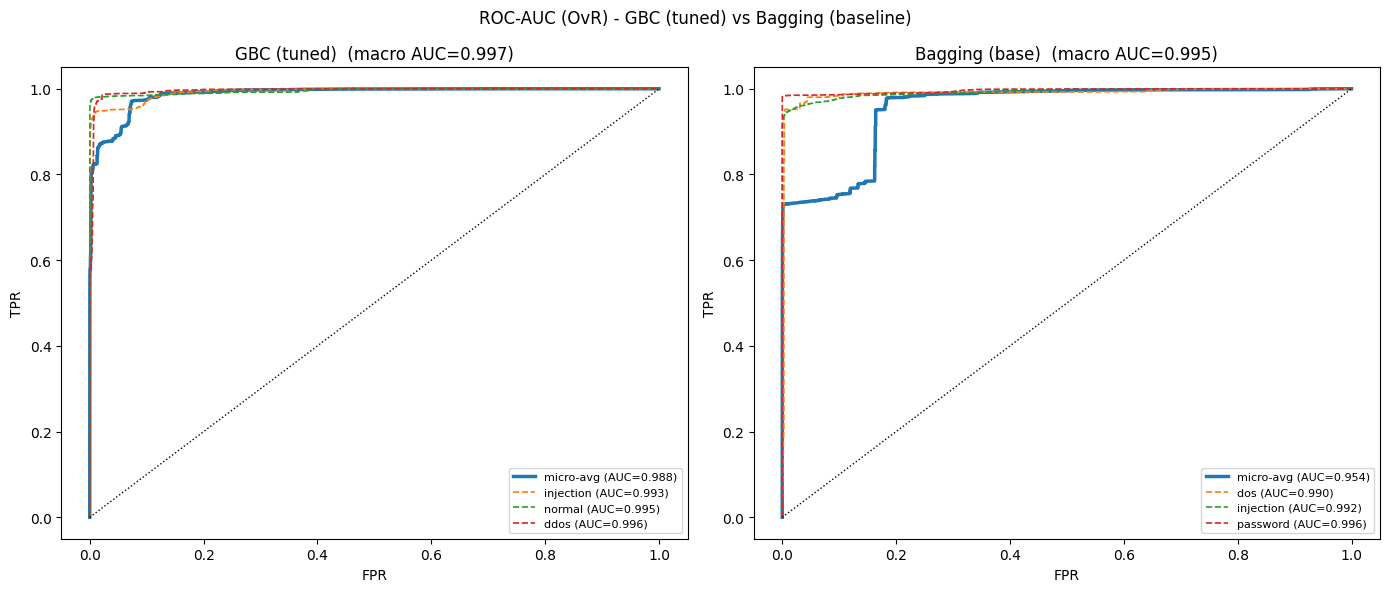

In [29]:
# --- ROC-AUC (OvR): GBC (tuned) vs Bagging (baseline), test set ---
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
Y_bin = label_binarize(np.asarray(y_te, dtype=object), classes=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, _name in zip(axes, ['GBC (tuned)', 'Bagging (base)']):
    _proba = cmp_cache[_name].predict_proba(X_te)
    # one probability column per class in the test fold, in LABELS order
    _S = _proba[:, [list(cmp_cache[_name].classes_).index(_c) for _c in LABELS]]
    _fpr, _tpr, _auc = {}, {}, {}
    for _i, _c in enumerate(LABELS):
        _fpr[_c], _tpr[_c], _ = roc_curve(Y_bin[:, _i], _S[:, _i])
        _auc[_c] = auc(_fpr[_c], _tpr[_c])
    _fpr['micro'], _tpr['micro'], _ = roc_curve(Y_bin.ravel(), _S.ravel())
    _auc['micro'] = auc(_fpr['micro'], _tpr['micro'])
    _auc['macro'] = float(np.mean([_auc[_c] for _c in LABELS]))
    ax.plot(_fpr['micro'], _tpr['micro'], lw=2.5,
            label='micro-avg (AUC=%.3f)' % _auc['micro'])
    _worst = sorted(LABELS, key=lambda _c: _auc[_c])[:3]
    for _c in _worst:
        ax.plot(_fpr[_c], _tpr[_c], lw=1.2, ls='--',
                label='%s (AUC=%.3f)' % (_c, _auc[_c]))
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(_name + '  (macro AUC=%.3f)' % _auc['macro'])
    ax.legend(fontsize=8, loc='lower right')
fig.suptitle('ROC-AUC (OvR) - GBC (tuned) vs Bagging (baseline)')
os.makedirs(os.path.join(ROOT, 'results/figures/toniot_partB'), exist_ok=True)
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results/figures/toniot_partB/cls_roc_gbc_bag.png'), dpi=150, bbox_inches='tight')
print('Saved: results/figures/toniot_partB/cls_roc_gbc_bag.png')
plt.show()



Saved: results/figures/toniot_partB/cls_cm_4way.png


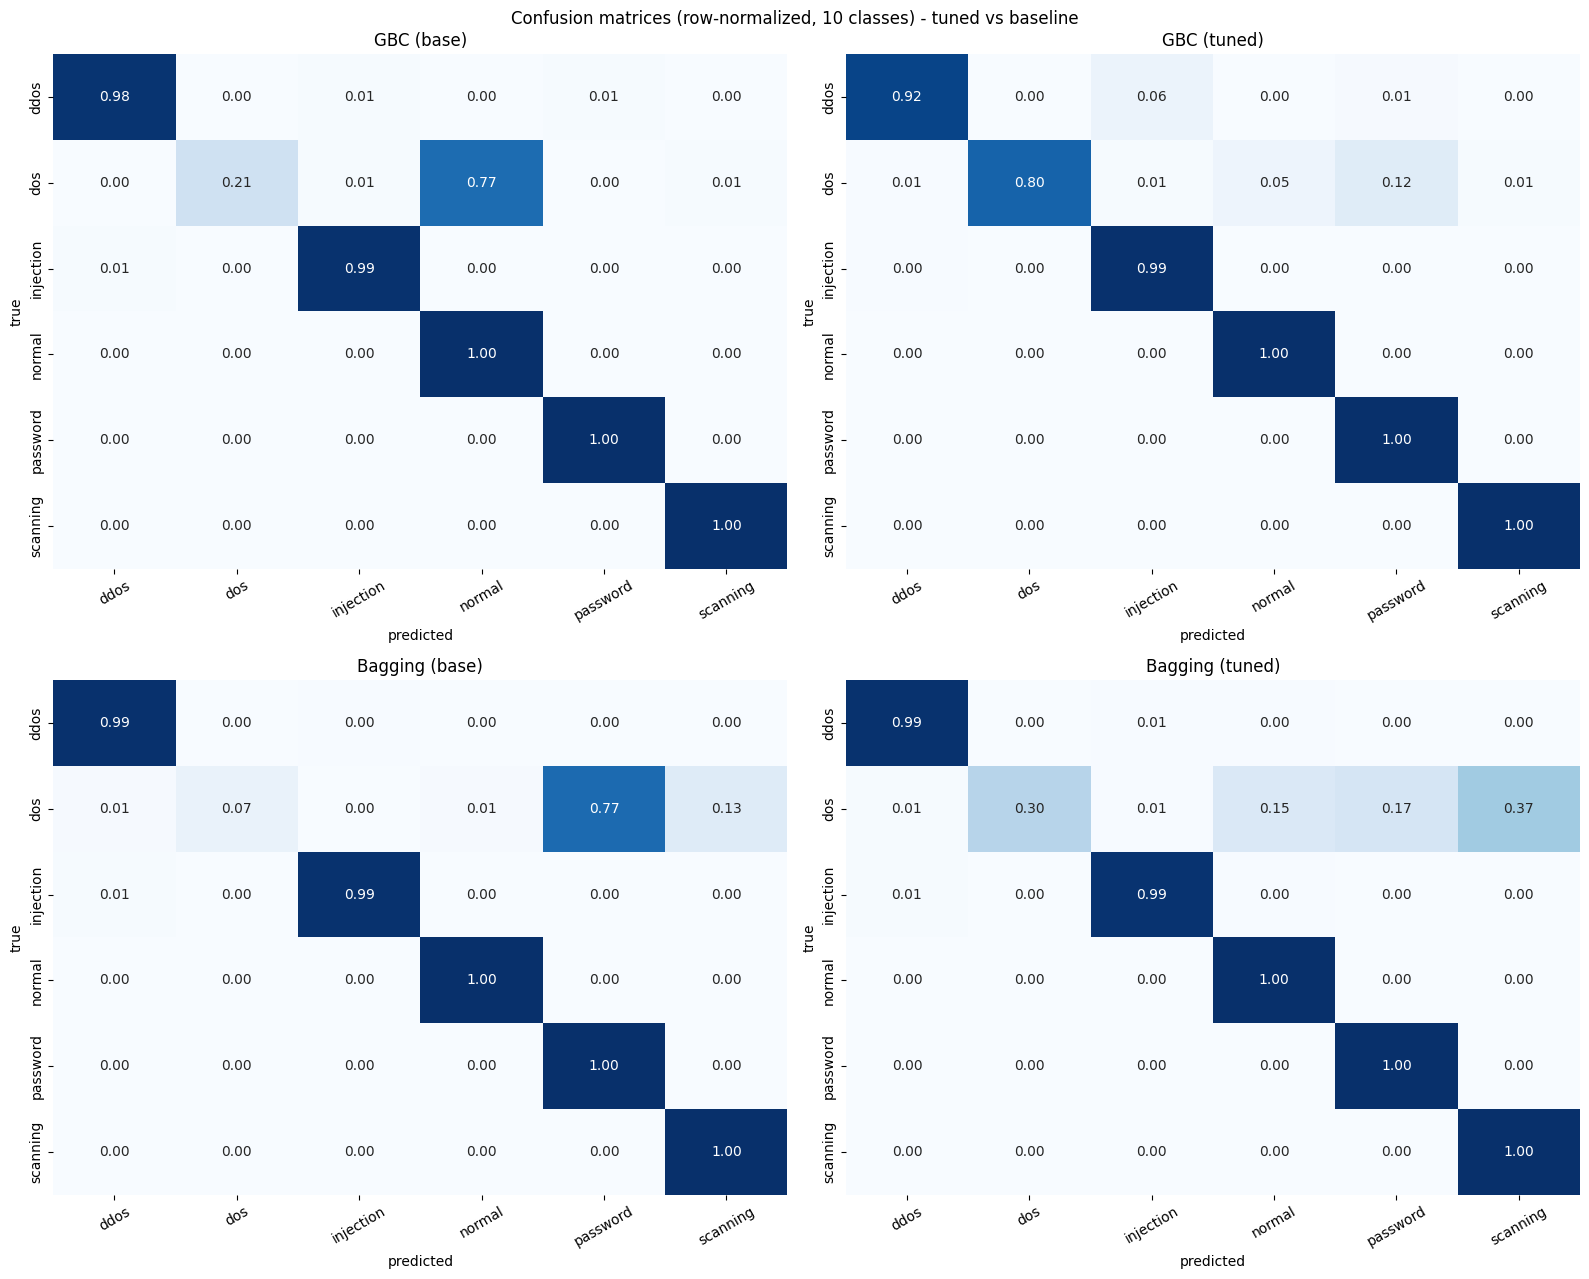

In [30]:
# --- Confusion matrices (row-normalized, all 10 classes, test set) ---
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, _name in zip(axes.ravel(), ['GBC (base)', 'GBC (tuned)',
                                   'Bagging (base)', 'Bagging (tuned)']):
    _cm = confusion_matrix(y_te, cmp_cache[_name].predict(X_te), labels=LABELS)
    _rs = _cm.sum(axis=1, keepdims=True)
    _cmn = np.divide(_cm, _rs, out=np.zeros_like(_cm, dtype=float), where=_rs != 0)
    sns.heatmap(_cmn, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(_name); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Confusion matrices (row-normalized, 10 classes) - tuned vs baseline')
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results/figures/toniot_partB/cls_cm_4way.png'), dpi=150, bbox_inches='tight')
print('Saved: results/figures/toniot_partB/cls_cm_4way.png')
plt.show()

